# 11 · Agente analista de growth

**Sesión 11 · Agentes** (LangGraph + Claude Sonnet 5.5). Un agente que responde preguntas de negocio sobre todo el lab con las cifras de las sesiones 1–10, y que no mueve plata sin aprobación humana (decisión 016).

```mermaid
flowchart LR
    P["Pregunta"] --> E["Enrutador<br/>(Claude)"]
    E --> C["Captación"]
    E --> R["Retención"]
    E --> B["Presupuesto"]
    C & R & B --> K["Coordinador<br/>(Claude)"]
    K --> G{"Reglas en código<br/>±30% · total ≤ hoy<br/>búsqueda congelada"}
    G -- "falla" --> K
    G -- "propuesta" --> H{"Humano<br/>aprueba"}
    G -- "consulta" --> F["Respuesta"]
    H --> F
```

Cada especialista usa SQL de solo lectura (`db.consultar()`) y herramientas que leen los resultados de su área, y recibe las decisiones vigentes de su área. Este notebook **no llama a la API**: lee las corridas guardadas en `data/processed/agt_demo.parquet` (`python -c "from growth_lab import agente; agente.demo()"`).

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from growth_lab import agente, db

pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
demo = pd.read_parquet(db.PROCESSED / "agt_demo.parquet")

## 1. Costo y tiempo por versión

- **v1:** primera corrida. **v2:** búsqueda congelada por regla y decisiones vigentes en cada especialista. **v3:** objetivo utilidad (no ventas) y total ≤ hoy; solo se re-corrieron las dos preguntas de presupuesto.

In [2]:
demo.groupby("version").agg(preguntas=("pregunta", "size"), llamadas=("llamadas", "sum"),
                            costo_usd=("costo_usd", "sum"), segundos_mediana=("segundos", "median")).round(3)

,preguntas,llamadas,costo_usd,segundos_mediana
version,,,,
v1,7,33,0.333,18.976
v2,7,32,0.326,19.079
v3,2,9,0.106,26.771


## 2. Qué hizo el agente con cada pregunta (v2)

In [3]:
demo[demo.version == "v2"][["pregunta", "especialistas", "herramientas", "estado", "costo_usd"]].round(3)

,pregunta,especialistas,herramientas,estado,costo_usd
7,¿Qué canal de Olist trae los leads más valiosos y cuánto puedo pagar como máximo por c...,captacion,valor_canales,respondida,0.032
8,¿Qué segmento de clientes debo priorizar para retención y cuánto gasto está en riesgo?,retencion,segmentos_clv,respondida,0.031
9,¿Vale la pena seguir mandando el correo de Hillstrom? ¿A quién se lo mando?,retencion,"experimentos_uplift, tablas, consultar_sql, consultar_sql, consultar_sql",respondida,0.076
10,¿Display está sobrevalorado? Compara lo que dicen la atribución y el MMM.,presupuesto,"atribucion, mmm",respondida,0.039
11,¿Dónde pongo el siguiente peso: en captar leads de búsqueda pagada o en retener a los ...,"captacion, retencion","valor_canales, segmentos_clv, campanas, experimentos_uplift",respondida,0.064
12,"Propón cómo repartir el presupuesto de medios del próximo año entre canales, con el mi...",presupuesto,"mmm, atribucion, simular_reparto, simular_reparto, simular_reparto","rechazada: El objetivo es utilidad, no ventas: lo que no rinde sobre el equilibrio que...",0.077
13,¿Cuál es la tasa de interés del Banco de la República este mes?,,,respondida,0.006


## 3. Leer las decisiones cambia la respuesta: retención, v1 contra v2

En v1 el especialista solo miró la tabla de segmentos y priorizó un segmento. En v2 recibió la decisión 007 (priorizar por hogar) y la 012 (control sorteado).

In [4]:
q = agente.DEMO[1]
for v in ["v1", "v2"]:
    print(f"--- {v} ---")
    print(demo[(demo.version == v) & (demo.pregunta == q)].respuesta.iloc[0], "\n")

--- v1 ---
Prioriza el segmento Núcleo. Tiene 778 hogares (31,8 % de la base) y el CLV a 13 semanas más alto (957). Aunque su churn parcial es el más bajo (9,9 %), 278 de sus hogares están en el top 20 % de riesgo, y por eso concentra el mayor gasto en riesgo: 37.039 de unos 73.848 en toda la base, cerca del 50 %. Enfriándose tiene más churn (26,8 %) pero solo 12.562 en riesgo; Dormidos (36,8 %) apenas tiene 1.172 que proteger. Son agregados que no miden el efecto de una acción de retención: para saber si conviene actuar sobre el Núcleo haría falta el análisis de uplift (experimentos_uplift), que no se ha consultado. 

--- v2 ---
Prioriza Núcleo. Es el segmento con más gasto en riesgo: unos 37.039 USD, cerca del 50% del total de la base (≈73.848 USD), aunque tiene la probabilidad media de churn más baja (11%) y el CLV más alto (957 USD por hogar a 13 semanas). Por la decisión 007, la retención se prioriza por hogar y no por segmento. Conviene empezar por los 278 hogares de Núcleo que e

## 4. Las tres propuestas de reparto y lo que decidí

Se evalúan las tres con la misma vara: utilidad extra en el año = ventas extra × 30% − gasto extra, según el MMM y según la verdad del simulador (solo existe en el lab).

In [5]:
herr = agente.Herramientas()
filas = []
for _, r in demo[demo.propuesta != "[]"].iterrows():
    cambios = json.loads(r.propuesta)
    s = herr.simular_reparto(cambios)
    filas.append({"version": r.version, **{c["canal"]: c["cambio_pct"] for c in cambios},
                  "gasto_plan": s["gasto_anual_plan"], "utilidad_modelo": s["utilidad_extra_segun_modelo"],
                  "utilidad_verdad": s["utilidad_extra_verdad_simulador"], "humano": r.estado})
plan = herr.plan_utilidad()
filas.append({"version": "máximo (plan_utilidad)", **{c["canal"]: c["cambio_pct"] for c in plan["cambios"]},
              "gasto_plan": plan["simulacion"]["gasto_anual_plan"],
              "utilidad_modelo": plan["simulacion"]["utilidad_extra_segun_modelo"],
              "utilidad_verdad": plan["simulacion"]["utilidad_extra_verdad_simulador"], "humano": "no propuesto"})
props = pd.DataFrame(filas).fillna(0)
props.round(1)

,version,tv,paid_search,social,display,email,gasto_plan,utilidad_modelo,utilidad_verdad,humano
0,v1,10.1,18.3,-30.0,-18.8,30.0,8761.1,117.2,183.2,rechazada: Búsqueda no sube hasta tener la prueba geo (decisión 015).
1,v2,26.5,0.0,-30.0,-19.0,30.0,8756.6,51.9,131.3,"rechazada: El objetivo es utilidad, no ventas: lo que no rinde sobre el equilibrio que..."
2,v3,10.0,0.0,-30.0,-19.0,30.0,8288.8,274.1,324.1,aprobada: Plan 015 sin búsqueda y con reserva; recorte grande solo tras la prueba regi...
3,máximo (plan_utilidad),-30.0,-14.6,-30.0,-30.0,-3.1,6569.8,706.4,769.8,no propuesto


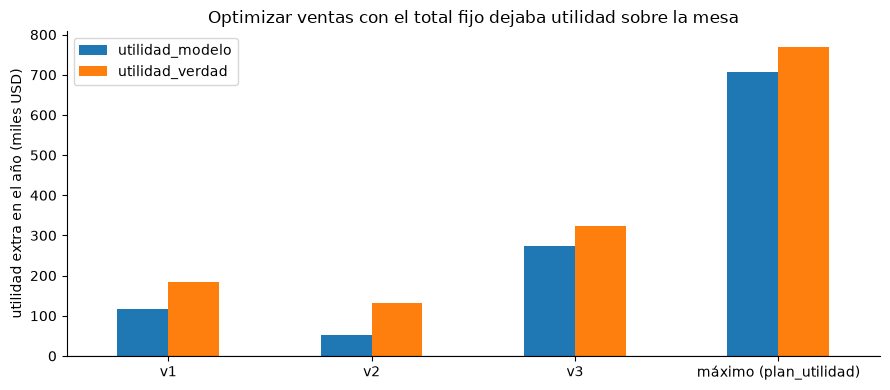

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
p = props.set_index("version")[["utilidad_modelo", "utilidad_verdad"]]
p.plot.bar(ax=ax, rot=0)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("utilidad extra en el año (miles USD)")
ax.set_xlabel("")
ax.set_title("Optimizar ventas con el total fijo dejaba utilidad sobre la mesa")
fig.tight_layout(); fig.savefig("../docs/img/agt_propuestas.png", dpi=150); plt.show()

## Mis conclusiones (Neider)

1. **El agente responde bien lo que ya está calculado:** 7 preguntas por unos USD 0,33, con cifras citadas por herramienta, y dice "no sé" cuando falta el dato (CPL real de búsqueda) o la pregunta no es del lab.
2. **Sin mis decisiones, el agente improvisa:** en v1 priorizó un segmento y subió búsqueda. Desde v2 cada especialista lee las decisiones vigentes de su área y la regla de búsqueda congelada vive en código, no en el prompt.
3. **El agente me corrigió a mí:** al pedirle el mismo total sin subir búsqueda, tuvo que subir TV +26,5% y eso deja menos utilidad. El objetivo correcto es utilidad, no ventas: con lo que sobra en reserva gano +324 mil en vez de +131 mil.
4. **Firmé la v3:** TV +10%, e-mail +30%, social −30%, display −19%, búsqueda congelada y 471 mil en reserva. El recorte grande (gasto −25%) espera la prueba regional.
5. **Lo que falta medir** (sesión 12): que cada cifra de la respuesta salga de una herramienta, con casos dorados y un juez, y registrar cada ejecución.